Analyzing Monthly Job Demand in Morocco
steps : 
Data cleaning and preparation
Data management
Extract from datetime
Pivot tables
Index management

In [1]:
# Importing Libraries
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [2]:
# creat a copy of our Data Frame and only include roles that are in Morocco
df_Mac = df[df['job_country'] == 'Morocco'].copy()

In [3]:
df_Mac.head()

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
1836,Data Analyst,Data Analyst,Morocco,via تنقيب,Full-time,False,Morocco,2023-10-10 13:30:18,False,False,Morocco,NaN,NaN,NaN,Confidentiel,"['sql', 'python', 'r', 'php', 'java', 'postgre...","{'analyst_tools': ['tableau'], 'databases': ['..."
1991,Data Engineer,Data Engineer (H/F),"Rabat, Morocco",via LinkedIn,Full-time,False,Morocco,2023-11-30 13:19:30,False,False,Morocco,NaN,NaN,NaN,Orange Business,"['sql', 'powershell', 'oracle', 'hadoop', 'lin...","{'async': ['jira', 'confluence'], 'cloud': ['o..."
2109,Data Scientist,Data Scientist,"Tangier, Morocco",via ReKrute.com,Full-time,False,Morocco,2023-12-20 13:16:44,False,False,Morocco,NaN,NaN,NaN,Altados,"['python', 'r', 'sql', 'elasticsearch', 'spark...","{'databases': ['elasticsearch'], 'libraries': ..."
2225,Data Scientist,Data Scientist / Professeur en Data science,Morocco,via Nature,Full-time,False,Morocco,2023-10-19 14:10:18,False,False,Morocco,NaN,NaN,NaN,Mohammed VI Polytechnic University,"['r', 'python', 'matlab']","{'programming': ['r', 'python', 'matlab']}"
2728,Data Scientist,Data scientist,"Rabat, Morocco",via SmartRecruiters Job Search,Full-time,False,Morocco,2023-11-24 13:18:28,False,False,Morocco,NaN,NaN,NaN,ALTEN,"['r', 'sql', 'postgresql']","{'databases': ['postgresql'], 'programming': [..."


In [4]:
# extract the month name from 'job_posted_date'
df_Mac['job_posted_month'] = df_Mac['job_posted_date'].dt.to_period('M')

In [5]:
df_Mac_pivot =df_Mac.pivot_table(index = 'job_posted_month', columns ='job_title_short', aggfunc= 'size' )

In [6]:
df_Mac_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
2023-01,15.0,4.0,36.0,51.0,36.0,5.0,5.0,9.0,5.0,13.0
2023-02,8.0,2.0,33.0,26.0,19.0,2.0,5.0,2.0,5.0,1.0
2023-03,10.0,1.0,30.0,43.0,28.0,4.0,NaN,11.0,2.0,2.0
2023-04,7.0,4.0,33.0,22.0,13.0,1.0,3.0,5.0,5.0,6.0
2023-05,2.0,6.0,21.0,24.0,13.0,1.0,3.0,4.0,3.0,4.0
2023-06,7.0,3.0,25.0,27.0,11.0,1.0,2.0,3.0,1.0,2.0
2023-07,14.0,3.0,29.0,37.0,12.0,6.0,5.0,3.0,3.0,7.0
2023-08,13.0,5.0,33.0,25.0,23.0,NaN,4.0,3.0,7.0,14.0
2023-09,10.0,NaN,22.0,28.0,8.0,3.0,6.0,5.0,4.0,3.0


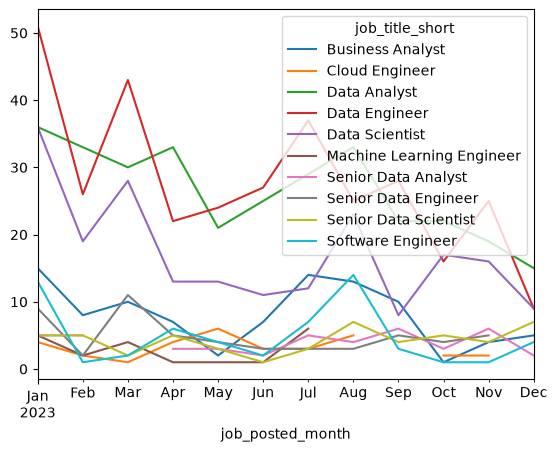

In [7]:
df_Mac_pivot.plot(kind = 'line')
plt.show()

In [8]:
top_3 = df_Mac['job_title_short'].value_counts().head(3)
top_3= top_3.index.tolist()
top_3

['Data Engineer', 'Data Analyst', 'Data Scientist']

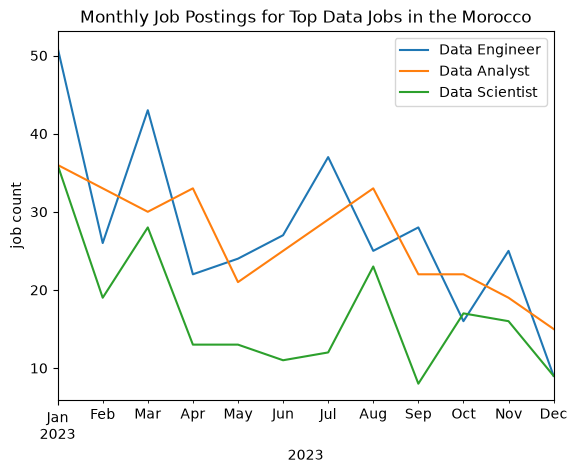

In [9]:
df_Mac_pivot[top_3].plot(kind = 'line')
plt.ylabel('job count')
plt.xlabel('2023')
plt.title('Monthly Job Postings for Top Data Jobs in the Morocco')
plt.legend()
plt.show()